# Veri Madenciliği Projesi – Notebook 1: Veri Hazırlama ve Keşifsel Veri Analizi
**Öğrenci:** Ömer Uslusoy (26221004006)
**Veri:** CDC BRFSS 2025 (356.158 kişi)

## 1. Soru ve bağlam
**Amaç:** ABD'li yetişkinlerde sık ruhsal sıkıntının (son 30 günde 14 gün ve üzeri kötü ruh sağlığı) sağlık davranışları, kronik hastalıklar, sağlık hizmetine erişim ve sosyodemografik özelliklerden tahmin edilmesi (ikili sınıflandırma).

**Veri kaynağı:** BRFSS, ABD Hastalık Kontrol Merkezi'nin (CDC) her yıl yetişkinlerle yaptığı telefon anketidir. Bir satır = bir katılımcı.

**Neden önemli:** Sık ruhsal sıkıntı yaşayan grupları tanımak, halk sağlığı taramalarının ve önleyici hizmetlerin hedeflenmesine yardımcı olur.

In [1]:
# Drive'ı bağla ve kullanılacak kütüphaneleri yükle
from google.colab import drive
drive.mount('/content/drive')

import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42   # rastgele işlemlerin her çalıştırmada aynı sonucu vermesi için

# Veri dosyasını Drive'da bul (klasör yolu değişse de çalışır)
yol = glob.glob('/content/drive/MyDrive/**/brfss2025.parquet', recursive=True)[0]
klasor = yol.rsplit('/', 1)[0]
print('Veri dosyası:', yol)

Mounted at /content/drive
Veri dosyası: /content/drive/MyDrive/YL: Yapay Zeka/VeriMadenciligi/veri/brfss2025.parquet


## 2. Değişken seçimi
Ham veride 283 sütun var. Temel anketten, eksikliği düşük 39 öznitelik seçildi (6 sayısal, 33 kategorik). Ruh sağlığını doğrudan ölçen değişkenler (MENTHLTH, POORHLTH, ADDEPEV3, DECIDE, DIFFALON) veri sızıntısını önlemek için modele alınmadı. Seçim gerekçeleri raporda veri sözlüğü tablosunda verilmiştir.

In [2]:
# Gruplara göre seçilen 39 öznitelik
OZNITELIKLER = {
    'Demografi':       ['_AGE80', 'SEXVAR', '_RACEGR3', '_EDUCAG', '_INCOMG1', 'MARITAL',
                        'EMPLOY1', 'CHILDREN', 'VETERAN3', 'RENTHOM1', '_URBSTAT', '_STATE'],
    'Saglik hizmeti':  ['_HLTHPL2', 'PERSDOC3', 'MEDCOST1', 'CHECKUP1'],
    'Davranis':        ['_TOTINDA', 'SLEPTIM1', '_SMOKER3', '_CURECI3', '_RFBING6',
                        '_RFDRHV9', 'ALCDAY4', '_BMI5'],
    'Kronik hastalik': ['_MICHD', 'CVDSTRK3', '_ASTHMS1', 'CHCCOPD3', 'CHCKDNY2',
                        'DIABETE4', 'HAVARTH4', 'CHCSCNC1', 'CHCOCNC1'],
    'Islevsel guclik': ['DEAF', 'BLIND', 'DIFFWALK', 'DIFFDRES'],
    'Genel saglik':    ['GENHLTH', 'PHYSHLTH'],
}
oznitelik_listesi = [c for grup in OZNITELIKLER.values() for c in grup]
print('Öznitelik sayısı:', len(oznitelik_listesi))   # 39 olmalı

# Yalnızca gereken sütunları oku: kişi numarası (SEQNO) + hedef + 39 öznitelik
ham = pd.read_parquet(yol, columns=['SEQNO', '_MENT14D'] + oznitelik_listesi)
print('Okunan tablo (satır, sütun):', ham.shape)

Öznitelik sayısı: 39
Okunan tablo (satır, sütun): (356158, 41)


## 3. Hedef değişkenin oluşturulması
CDC'nin hesapladığı _MENT14D değişkeni: 1 = 0 gün, 2 = 1-13 gün, 3 = 14+ gün, 9 = bilmiyor/reddetti/eksik.
İkili hedef: 3 → 1 (sık ruhsal sıkıntı); 1 ve 2 → 0. Kod 9, "sıkıntı yok" sayılmaması için 0'a çevrilmedi; bu kayıtlar analizden çıkarıldı ve sayısı aşağıda raporlandı.

In [3]:
print('_MENT14D dağılımı:')
print(ham['_MENT14D'].value_counts().sort_index(), '\n')

# Kod 9'u çıkar, ikili hedefi oluştur
cikarilan = (ham['_MENT14D'] == 9).sum()
df = ham[ham['_MENT14D'] != 9].copy()
df['hedef'] = (df['_MENT14D'] == 3).astype(int)
df = df.drop(columns='_MENT14D')

print(f'Çıkarılan (kod 9): {cikarilan:,} kişi (%{cikarilan / len(ham) * 100:.1f})')
print(f'Analiz örneklemi: {len(df):,} kişi')
print('\nHedef dağılımı:')
print(df['hedef'].value_counts())
print((df['hedef'].value_counts(normalize=True) * 100).round(1))

_MENT14D dağılımı:
_MENT14D
1.0    208060
2.0     91402
3.0     50212
9.0      6484
Name: count, dtype: int64 

Çıkarılan (kod 9): 6,484 kişi (%1.8)
Analiz örneklemi: 349,674 kişi

Hedef dağılımı:
hedef
0    299462
1     50212
Name: count, dtype: int64
hedef
0    85.6
1    14.4
Name: proportion, dtype: float64


**Yorum:** 6.484 kişi (%1,8) hedef değişkeni bilinmediği için çıkarıldı; bu oran düşük olduğundan örneklemin temsil gücünü önemli ölçüde etkilemez. Analiz örneklemi 349.674 kişidir. Sık ruhsal sıkıntı yaşayanlar %14,4 (50.212 kişi), yaşamayanlar %85,6'dır; sınıflar yaklaşık 1:6 oranında dengesizdir. Bu nedenle model başarısı doğrulukla (accuracy) değil F1 ve ROC-AUC ile ölçülecektir: herkese "sıkıntı yok" diyen bir model bile %85,6 doğruluk alır.

In [4]:
# Seçilmiş veriyi kaydet: sonraki adımlar bu küçük dosyadan hızlıca başlar
df.to_parquet(klasor + '/brfss_secili.parquet')
print('Kaydedildi:', klasor + '/brfss_secili.parquet', df.shape)

Kaydedildi: /content/drive/MyDrive/YL: Yapay Zeka/VeriMadenciligi/veri/brfss_secili.parquet (349674, 41)


## 4. Veri temizleme
### 4.1 Özel kodların çözülmesi
BRFSS'te cevapsızlık boş hücre yerine sayısal kodlarla tutulur: tek haneli sorularda 7 = bilmiyor, 9 = reddetti; iki haneli sorularda 77 / 99. Bu kodlar sayı gibi işlenirse ortalamaları ve modelleri bozar (ör. 99 saat uyku). Bu nedenle eksik değere (NaN) çevrildi. 88 = "hiç" kodu eksik değil, sıfır anlamına geldiği için 0 yapıldı.
Ayrıca: BMI 2 ondalıklı kodlandığı için 100'e bölündü; alkol sorusu (haftalık ve aylık iki kodlama karışık) "son 30 günde alkol alınan gün sayısına" çevrildi; son kontrol zamanında "hiç" (8) en uç sıra olarak 5 yapıldı.

In [5]:
temiz = df.copy()
bos_once = temiz.isna().sum()          # temizlikten önce zaten boş olan hücreler
kodlu_eksik = {}                       # kod nedeniyle eksik yapılan hücre sayısı

def kodu_eksik_yap(sutun, kodlar):
    maske = temiz[sutun].isin(kodlar)
    kodlu_eksik[sutun] = int(maske.sum())
    temiz.loc[maske, sutun] = np.nan

# Değişkenleri cevapsızlık kodlarına göre grupla (kodlar 2025 codebook'undan)
KOD_9    = ['_RACEGR3', '_EDUCAG', '_INCOMG1', 'MARITAL', 'EMPLOY1', '_HLTHPL2', '_TOTINDA',
            '_SMOKER3', '_CURECI3', '_RFBING6', '_RFDRHV9', '_ASTHMS1']
KOD_7_9  = ['VETERAN3', 'RENTHOM1', 'PERSDOC3', 'MEDCOST1', 'CHECKUP1', 'CVDSTRK3', 'CHCCOPD3',
            'CHCKDNY2', 'DIABETE4', 'HAVARTH4', 'CHCSCNC1', 'CHCOCNC1', 'DEAF', 'BLIND',
            'DIFFWALK', 'DIFFDRES', 'GENHLTH']
KOD_77_99 = ['SLEPTIM1', 'PHYSHLTH']

for s in KOD_9:     kodu_eksik_yap(s, [9])
for s in KOD_7_9:   kodu_eksik_yap(s, [7, 9])
for s in KOD_77_99: kodu_eksik_yap(s, [77, 99])
kodu_eksik_yap('CHILDREN', [99])

# 88 = "hiç" → 0
temiz['CHILDREN'] = temiz['CHILDREN'].replace(88, 0)
temiz['PHYSHLTH'] = temiz['PHYSHLTH'].replace(88, 0)

# Son kontrol: 1 = son 1 yıl ... 4 = 5+ yıl önce, 8 = hiç → 5 (en uç sıra)
temiz['CHECKUP1'] = temiz['CHECKUP1'].replace(8, 5)

# BMI: 2 ondalıklı kod → gerçek değer (2663 → 26.63)
temiz['_BMI5'] = temiz['_BMI5'] / 100

# Alkol: 101-107 = haftada gün, 201-230 = son 30 günde gün, 888 = hiç, 777/999 = cevapsız
a = temiz['ALCDAY4']
kodlu_eksik['ALCDAY4'] = int(a.isin([777, 999]).sum())
gun = pd.Series(np.nan, index=a.index)
gun[a == 888] = 0
haftalik = a.between(101, 107)
gun[haftalik] = (a[haftalik] - 100) * 30 / 7      # haftada x gün → ayda yaklaşık x·30/7 gün
aylik = a.between(201, 230)
gun[aylik] = a[aylik] - 200
temiz['ALKOL_GUN'] = gun.round(1)
temiz = temiz.drop(columns='ALCDAY4')

print('Temizlik tamam. Tablo boyutu:', temiz.shape)

Temizlik tamam. Tablo boyutu: (349674, 41)


### 4.2 Eksik veri analizi

In [6]:
# Eksik veri tablosu: önceden boş olanlar + kod nedeniyle eksik yapılanlar
bos_once = bos_once.rename({'ALCDAY4': 'ALKOL_GUN'})
kodlu = pd.Series(kodlu_eksik).rename({'ALCDAY4': 'ALKOL_GUN'})
eksik_tablo = pd.DataFrame({'bos_hucre': bos_once, 'cevapsiz_kod': kodlu}).fillna(0).astype(int)
eksik_tablo = eksik_tablo.drop(index=['SEQNO', 'hedef'])
eksik_tablo['toplam_eksik'] = temiz[eksik_tablo.index].isna().sum()
eksik_tablo['eksik_%'] = (eksik_tablo['toplam_eksik'] / len(temiz) * 100).round(2)
eksik_tablo = eksik_tablo.sort_values('eksik_%', ascending=False)
print('Tablo 1. Değişkenlere göre eksik veri')
display(eksik_tablo)

# Kontrol: sayısal değişkenlerde artık anlamsız kod (77, 88, 99...) kalmamalı
print('\nTablo 2. Sayısal değişkenlerin özeti (temizlik sonrası)')
display(temiz[['_AGE80', 'CHILDREN', 'SLEPTIM1', 'PHYSHLTH', '_BMI5', 'ALKOL_GUN']].describe().round(2))

Tablo 1. Değişkenlere göre eksik veri


,bos_hucre,cevapsiz_kod,toplam_eksik,eksik_%
_INCOMG1,0,68342,68342,19.54
_BMI5,31366,0,31366,8.97
_RFBING6,0,28307,28307,8.10
_RFDRHV9,0,27726,27726,7.93
SLEPTIM1,22141,3981,26122,7.47
ALKOL_GUN,22917,2972,25889,7.40
_CURECI3,0,20892,20892,5.97
_SMOKER3,0,19931,19931,5.70
DIFFWALK,14128,1288,15416,4.41
DIFFDRES,14738,556,15294,4.37



Tablo 2. Sayısal değişkenlerin özeti (temizlik sonrası)


,_AGE80,CHILDREN,SLEPTIM1,PHYSHLTH,_BMI5,ALKOL_GUN
count,349674.00,342150.00,323552.00,343169.00,318308.00,323785.00
mean,55.72,0.47,7.09,4.66,28.48,4.21
std,18.35,1.10,1.42,8.99,6.53,7.59
min,18.00,0.00,1.00,0.00,12.02,0.00
25%,41.00,0.00,6.00,0.00,24.11,0.00
50%,59.00,0.00,7.00,0.00,27.41,0.00
75%,72.00,0.00,8.00,4.00,31.62,4.30
max,80.00,84.00,24.00,30.00,98.43,30.00


**Yorum (Tablo 1):** Eksiklik değişkenlerin çoğunda %5'in altındadır. En yüksek eksiklik gelirde (%19,5): katılımcıların yaklaşık beşte biri gelir sorusunu yanıtlamamış ya da bilmediğini belirtmiştir; bu yanıtsızlık rastgele olmayabilir (MNAR olasılığı). BMI'de %9 eksiklik boy/kilo bilgisinin verilmemesinden kaynaklanır. Uyku, tütün ve alkol değişkenlerinde eksikliğin anketin ilerleyen bölümlerinde artması, bir kısmının yarıda bırakılan görüşmelerden kaynaklandığını düşündürmektedir; bu, eş-eksiklik analiziyle incelenecektir. Eksikliğin hedefle ilişkili olup olmadığı Bölüm 6.1'de incelenecek ve gösterge sütunu eklenip eklenmeyeceğine buna göre karar verilecektir.

**Yorum (Tablo 2):** Temizlik sonrası hiçbir sayısal değişkende 77/88/99 gibi kod değeri kalmamıştır. Fiziksel sağlığı kötü gün sayısı ve alkol günü sağa çarpıktır (medyan 0, ortalama sırasıyla 4,7 ve 4,2): katılımcıların çoğu 0 gün bildirirken küçük bir grup çok yüksek değerler bildirmiştir. Çocuk sayısında 84, uykuda 1 ve 24 saat, BMI'de 12 ve 98 gibi gerçekçi olmayan uç değerler vardır; bunlar silinmeden aykırı değer bölümünde incelenecektir.

### 4.3 Yinelenen kayıtlar

In [7]:
# 1) Aynı kişi iki kez var mı? (SEQNO yalnız eyalet içinde benzersiz → kimlik = eyalet + SEQNO)
kimlik = temiz['_STATE'].astype(str) + '_' + temiz['SEQNO'].astype(str)
print('Yinelenen kişi kimliği (eyalet + SEQNO):', kimlik.duplicated().sum())

# 2) Kişi numarası dışında tüm değerleri aynı olan satırlar
ayni = temiz.drop(columns='SEQNO').duplicated().sum()
print(f'Kişi numarası dışında birebir aynı satır: {ayni:,} (%{ayni / len(temiz) * 100:.2f})')

Yinelenen kişi kimliği (eyalet + SEQNO): 0
Kişi numarası dışında birebir aynı satır: 13 (%0.00)


**Yorum:** BRFSS'te SEQNO yalnızca eyalet içinde benzersizdir; eyalet + SEQNO birleşimiyle aynı kişinin iki kez kaydedilmediği doğrulanmıştır. Kimlik dışında tüm değerleri aynı olan yalnızca 13 satır (%0,004) vardır; bunlar farklı kişilerin aynı yanıtları vermesiyle açıklanabileceğinden silinmemiştir.

In [8]:
# Temizlenmiş veriyi kaydet (EDA ve modelleme bu dosyadan başlayacak)
temiz.to_parquet(klasor + '/brfss_temiz.parquet')
print('Kaydedildi:', klasor + '/brfss_temiz.parquet', temiz.shape)

Kaydedildi: /content/drive/MyDrive/YL: Yapay Zeka/VeriMadenciligi/veri/brfss_temiz.parquet (349674, 41)


## 5. Eğitim / test ayrımı
Veri, keşifsel analizden ÖNCE bir kez ayrıldı: %80 eğitim, %20 test, hedef oranı korunarak (stratified). Bundan sonraki tüm analizler ve veriden öğrenilen tüm kararlar (aykırı değer sınırları, doldurma değerleri, öznitelik seçimi) yalnızca eğitim kümesinden yapılır; test kümesi en sonda bir kez, modelin dürüst değerlendirmesi için kullanılır. Bu, test bilgisinin modele sızmasını önler. Şimdiye kadarki temizlik adımları veriden öğrenilmeyen, kurala dayalı dönüşümler olduğu için ayrımdan önce yapılmıştır.

In [9]:
from sklearn.model_selection import train_test_split

egitim, test = train_test_split(temiz, test_size=0.20, stratify=temiz['hedef'],
                                random_state=RANDOM_STATE)

print(f'Eğitim: {len(egitim):,} kişi | Test: {len(test):,} kişi')
print(f'Hedef oranı – eğitim: %{egitim["hedef"].mean()*100:.2f} | test: %{test["hedef"].mean()*100:.2f}')

egitim.to_parquet(klasor + '/brfss_egitim.parquet')
test.to_parquet(klasor + '/brfss_test.parquet')
print('Kaydedildi: brfss_egitim.parquet ve brfss_test.parquet')

Eğitim: 279,739 kişi | Test: 69,935 kişi
Hedef oranı – eğitim: %14.36 | test: %14.36
Kaydedildi: brfss_egitim.parquet ve brfss_test.parquet


**Yorum:** Eğitim kümesinde 279.739, test kümesinde 69.935 kişi vardır. Katmanlı (stratified) ayırma sayesinde sık ruhsal sıkıntı oranı iki kümede de %14,36'dır; test kümesi eğitimle aynı sınıf dağılımını taşır.

## 6. Keşifsel veri analizi (yalnızca eğitim kümesi, n = 279.739)
### 6.1 Eksik veri örüntüsü
İki soru incelenmiştir: (1) Eksiklikler aynı kişilerde birlikte mi görülüyor? (2) Bir değişkenin eksik olması hedefle ilişkili mi? İkincisi önemlidir: eksiklik hedefle ilişkiliyse rastgele değildir ve eksik değerleri yalnızca doldurmak bu bilgiyi kaybettirir.

Kişi başına eksik değişken sayısı (bu 11 değişken içinde):
0     193188
1      51413
2      11889
3       4844
4       2561
5       1405
6       1855
7       2102
8       1436
9       2100
10      6334
11       612
Name: count, dtype: int64


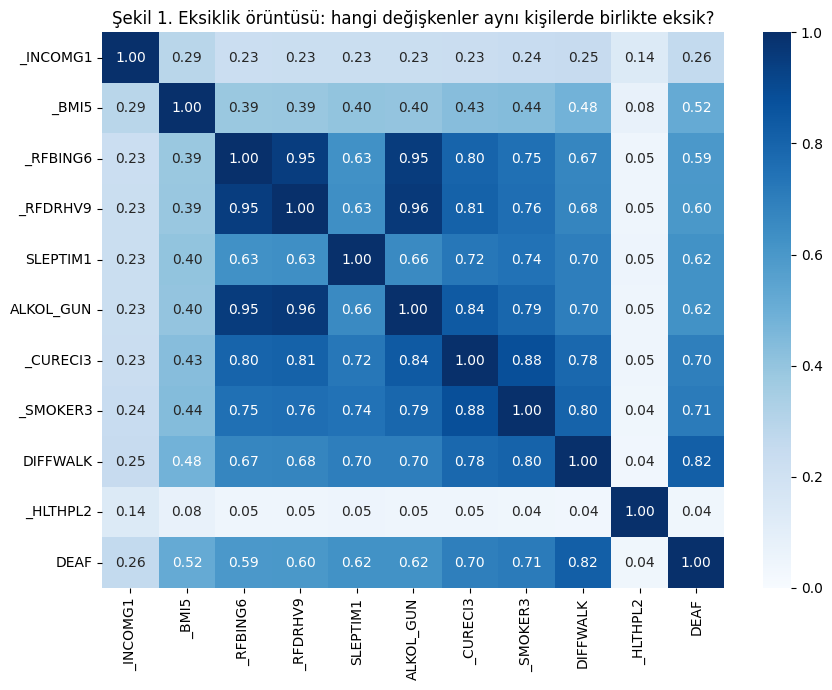

In [10]:
# %3'ten fazla eksikliği olan değişkenler
yuksek_eksik = ['_INCOMG1', '_BMI5', '_RFBING6', '_RFDRHV9', 'SLEPTIM1', 'ALKOL_GUN',
                '_CURECI3', '_SMOKER3', 'DIFFWALK', '_HLTHPL2', 'DEAF']
eksik = egitim[yuksek_eksik].isna().astype(int)    # 1 = eksik, 0 = dolu

# Bir kişide bu değişkenlerden kaçı eksik?
print('Kişi başına eksik değişken sayısı (bu 11 değişken içinde):')
print(eksik.sum(axis=1).value_counts().sort_index())

# Eksikliklerin birbiriyle ilişkisi (1'e yakın = aynı kişilerde birlikte eksik)
plt.figure(figsize=(9, 7))
sns.heatmap(eksik.corr(), annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1)
plt.title('Şekil 1. Eksiklik örüntüsü: hangi değişkenler aynı kişilerde birlikte eksik?')
plt.tight_layout()
plt.show()

**Yorum (Şekil 1):** Uyku, sigara, e-sigara, alkol ve engellilik sorularındaki eksiklikler büyük ölçüde aynı kişilerde birlikte görülmektedir (eksiklik korelasyonu 0,59–0,96). Kişi başına eksik sayısı iki tepelidir: katılımcıların %69'unda hiç eksik yokken 6.334 kişide 11 değişkenin 10'u birlikte eksiktir. Bu örüntü, BRFSS'in yarıda bırakılan görüşmeleri de veriye dahil etmesiyle uyumludur: görüşmeyi bırakan kişide sonraki bölümlerin tümü boş kalır. Gelirdeki eksiklik bu blokla zayıf ilişkilidir (0,14–0,29) ve farklı bir nedene (sorunun yanıtlanmaması) işaret eder; sağlık sigortası eksikliği ise bağımsızdır (≈0,05).

In [11]:
# Her değişken için: eksik olanlarda ve dolu olanlarda sık ruhsal sıkıntı oranı
satirlar = []
for s in yuksek_eksik:
    m = egitim[s].isna()
    satirlar.append({
        'degisken': s,
        'eksik_kisi': m.sum(),
        'sıkıntı_%_eksiklerde': egitim.loc[m, 'hedef'].mean() * 100,
        'sıkıntı_%_dolularda': egitim.loc[~m, 'hedef'].mean() * 100,
    })
tablo3 = pd.DataFrame(satirlar).set_index('degisken').round(1)
tablo3['fark_puan'] = (tablo3['sıkıntı_%_eksiklerde'] - tablo3['sıkıntı_%_dolularda']).round(1)
print('Tablo 3. Eksik olan ve olmayan gruplarda sık ruhsal sıkıntı oranı (genel oran %14,4)')
display(tablo3.sort_values('fark_puan', ascending=False))

Tablo 3. Eksik olan ve olmayan gruplarda sık ruhsal sıkıntı oranı (genel oran %14,4)


,eksik_kisi,sıkıntı_%_eksiklerde,sıkıntı_%_dolularda,fark_puan
degisken,,,,
_HLTHPL2,11692,15.1,14.3,0.8
SLEPTIM1,20955,14.7,14.3,0.4
_RFDRHV9,22204,14.3,14.4,-0.1
_RFBING6,22644,14.1,14.4,-0.3
ALKOL_GUN,20726,13.8,14.4,-0.6
_CURECI3,16751,13.4,14.4,-1.0
DEAF,10177,13.3,14.4,-1.1
DIFFWALK,12362,13.2,14.4,-1.2
_INCOMG1,54677,13.3,14.6,-1.3


**Yorum (Tablo 3):** Eksik olan ve olmayan gruplar arasında sık ruhsal sıkıntı oranı farkı küçüktür (−1,5 ile +0,8 puan; genel oran %14,4). Geliri bilinmeyenlerde oran beklenenin aksine biraz daha düşüktür (%13,3'e karşı %14,6). Eksikliğin hedef hakkında taşıdığı bilgi sınırlıdır. Bu nedenle her değişken için ayrı gösterge eklemek yerine iki gösterge oluşturulacaktır: gelir yanıtsızlığı (GELIR_EKSIK) ve uyku-tütün-alkol bloğunun tamamen eksik olması (KISMI_GORUSME). Bu göstergelerin model katkısı öznitelik seçiminde değerlendirilecektir.

### 6.2 Tek değişkenli dağılımlar
Sayısal değişkenler için histogram (ortalama ve medyan çizgileriyle), ikili değişkenler için "evet" oranları, sıralı ve nominal değişkenler için kategori yüzdeleri gösterilmiştir. Yüzdeler, ilgili değişkende eksik olmayan kişiler üzerinden hesaplanmıştır.

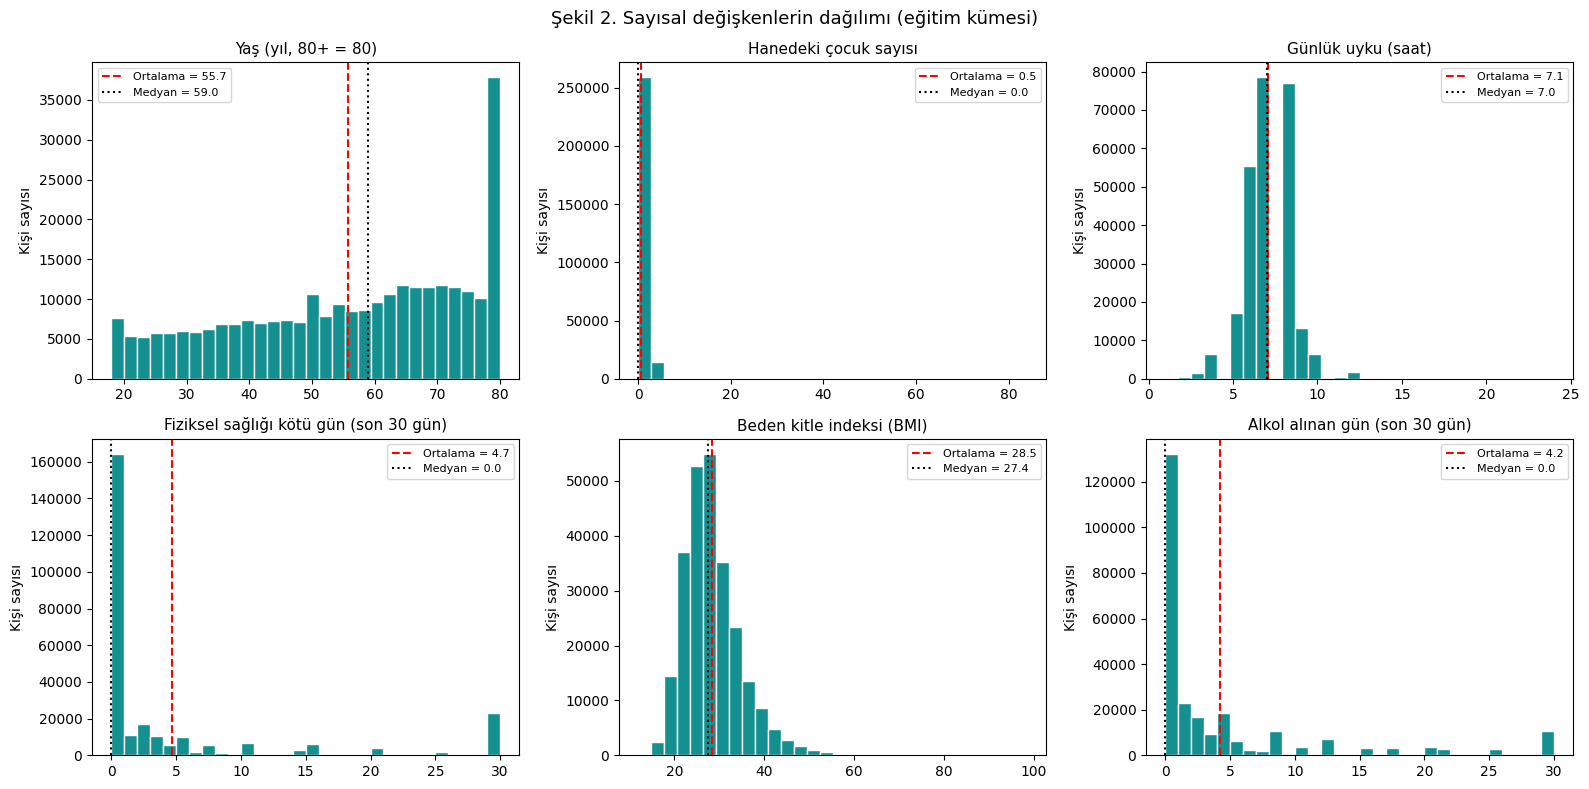

Çarpıklık (skewness):
_AGE80       -0.39
CHILDREN     13.25
SLEPTIM1      0.89
PHYSHLTH      2.04
_BMI5         1.42
ALKOL_GUN     2.22
dtype: float64


In [12]:
SAYISAL = {'_AGE80': 'Yaş (yıl, 80+ = 80)', 'CHILDREN': 'Hanedeki çocuk sayısı',
           'SLEPTIM1': 'Günlük uyku (saat)', 'PHYSHLTH': 'Fiziksel sağlığı kötü gün (son 30 gün)',
           '_BMI5': 'Beden kitle indeksi (BMI)', 'ALKOL_GUN': 'Alkol alınan gün (son 30 gün)'}

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (s, ad) in zip(axes.flat, SAYISAL.items()):
    x = egitim[s].dropna()
    ax.hist(x, bins=30, color='#159090', edgecolor='white')
    ax.axvline(x.mean(), color='red', ls='--', lw=1.5, label=f'Ortalama = {x.mean():.1f}')
    ax.axvline(x.median(), color='black', ls=':', lw=1.5, label=f'Medyan = {x.median():.1f}')
    ax.set_title(ad, fontsize=11)
    ax.set_ylabel('Kişi sayısı')
    ax.legend(fontsize=8)
fig.suptitle('Şekil 2. Sayısal değişkenlerin dağılımı (eğitim kümesi)', fontsize=13)
plt.tight_layout()
plt.show()

# Çarpıklık: 0 = simetrik, > 1 = belirgin sağa çarpık
print('Çarpıklık (skewness):')
print(egitim[list(SAYISAL)].skew().round(2))

**Yorum (Şekil 2):** Yaş dağılımı sola hafif çarpıktır (medyan 59) ve 80'de bir yığılma vardır (80 ve üstü yaşlar tek değerde toplanmıştır); örneklem ABD yetişkin nüfusundan yaşlıdır, çünkü anket ağırlıkları kullanılmamıştır. Uyku 7-8 saatte yoğunlaşır. Dört değişken belirgin sağa çarpıktır (çarpıklık > 1): çocuk sayısı (13,25; birkaç uç değer nedeniyle), alkol günü (2,22), fiziksel sağlığı kötü gün (2,04) ve BMI (1,42; medyan 27,4 ile örneklemin yarısı fazla kilolu sınırındadır). Fiziksel sağlıkta 0 ve 30 günde iki tepe vardır: katılımcılar ya hiç kötü gün yaşamamış ya da ayın tamamını kötü geçirmiştir. Alkol günündeki 4,3 / 8,6 / 12,9 tepeleri, haftalık yanıtların aylığa çevrilmesinden kaynaklanır (haftada 1, 2, 3 gün). Modellemede (Notebook 2) log dönüşümü uygulanmamış, sayısal değişkenler standartlaştırılmış; çocuk sayısındaki uç değerlerin etkisi 4'te kırpmayla sınırlandırılmıştır. Fiziksel sağlık değişkeni iki tepeli olduğu için log dönüşümüne zaten uygun değildir.

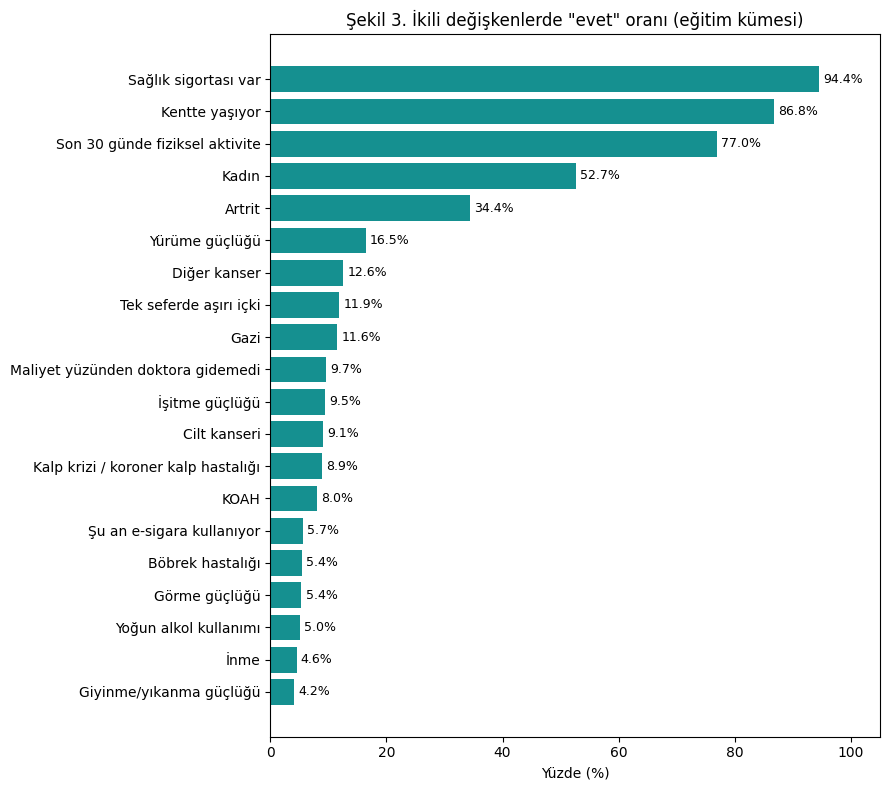

In [13]:
# Her ikili değişken için "evet" anlamına gelen kod ve Türkçe etiket (2025 codebook'undan)
IKILI = {'SEXVAR': (2, 'Kadın'), 'VETERAN3': (1, 'Gazi'), '_URBSTAT': (1, 'Kentte yaşıyor'),
         '_HLTHPL2': (1, 'Sağlık sigortası var'), 'MEDCOST1': (1, 'Maliyet yüzünden doktora gidemedi'),
         '_TOTINDA': (1, 'Son 30 günde fiziksel aktivite'), '_CURECI3': (2, 'Şu an e-sigara kullanıyor'),
         '_RFBING6': (2, 'Tek seferde aşırı içki'), '_RFDRHV9': (2, 'Yoğun alkol kullanımı'),
         '_MICHD': (1, 'Kalp krizi / koroner kalp hastalığı'), 'CVDSTRK3': (1, 'İnme'),
         'CHCCOPD3': (1, 'KOAH'), 'CHCKDNY2': (1, 'Böbrek hastalığı'), 'HAVARTH4': (1, 'Artrit'),
         'CHCSCNC1': (1, 'Cilt kanseri'), 'CHCOCNC1': (1, 'Diğer kanser'),
         'DEAF': (1, 'İşitme güçlüğü'), 'BLIND': (1, 'Görme güçlüğü'),
         'DIFFWALK': (1, 'Yürüme güçlüğü'), 'DIFFDRES': (1, 'Giyinme/yıkanma güçlüğü')}

oran = pd.Series({ad: (egitim[s] == kod).sum() / egitim[s].notna().sum() * 100
                  for s, (kod, ad) in IKILI.items()}).sort_values()

fig, ax = plt.subplots(figsize=(9, 8))
cubuklar = ax.barh(oran.index, oran.values, color='#159090')
ax.bar_label(cubuklar, fmt='%.1f%%', padding=3, fontsize=9)
ax.set_xlim(0, 105)
ax.set_xlabel('Yüzde (%)')
ax.set_title('Şekil 3. İkili değişkenlerde "evet" oranı (eğitim kümesi)')
plt.tight_layout()
plt.show()

**Yorum (Şekil 3):** Katılımcıların %94,4'ünün sağlık sigortası vardır, %77'si son 30 günde fiziksel aktivite yapmıştır. Kronik hastalıklar arasında en yaygını artrittir (%34,4); bu oran örneklemin yaşlı yapısıyla uyumludur. En nadir ikili değişkenler giyinme/yıkanma güçlüğü (%4,2) ve inmedir (%4,6). Hiçbir ikili değişken %4'ün altında olmadığı için düşük varyans nedeniyle elenecek değişken beklenmemektedir.

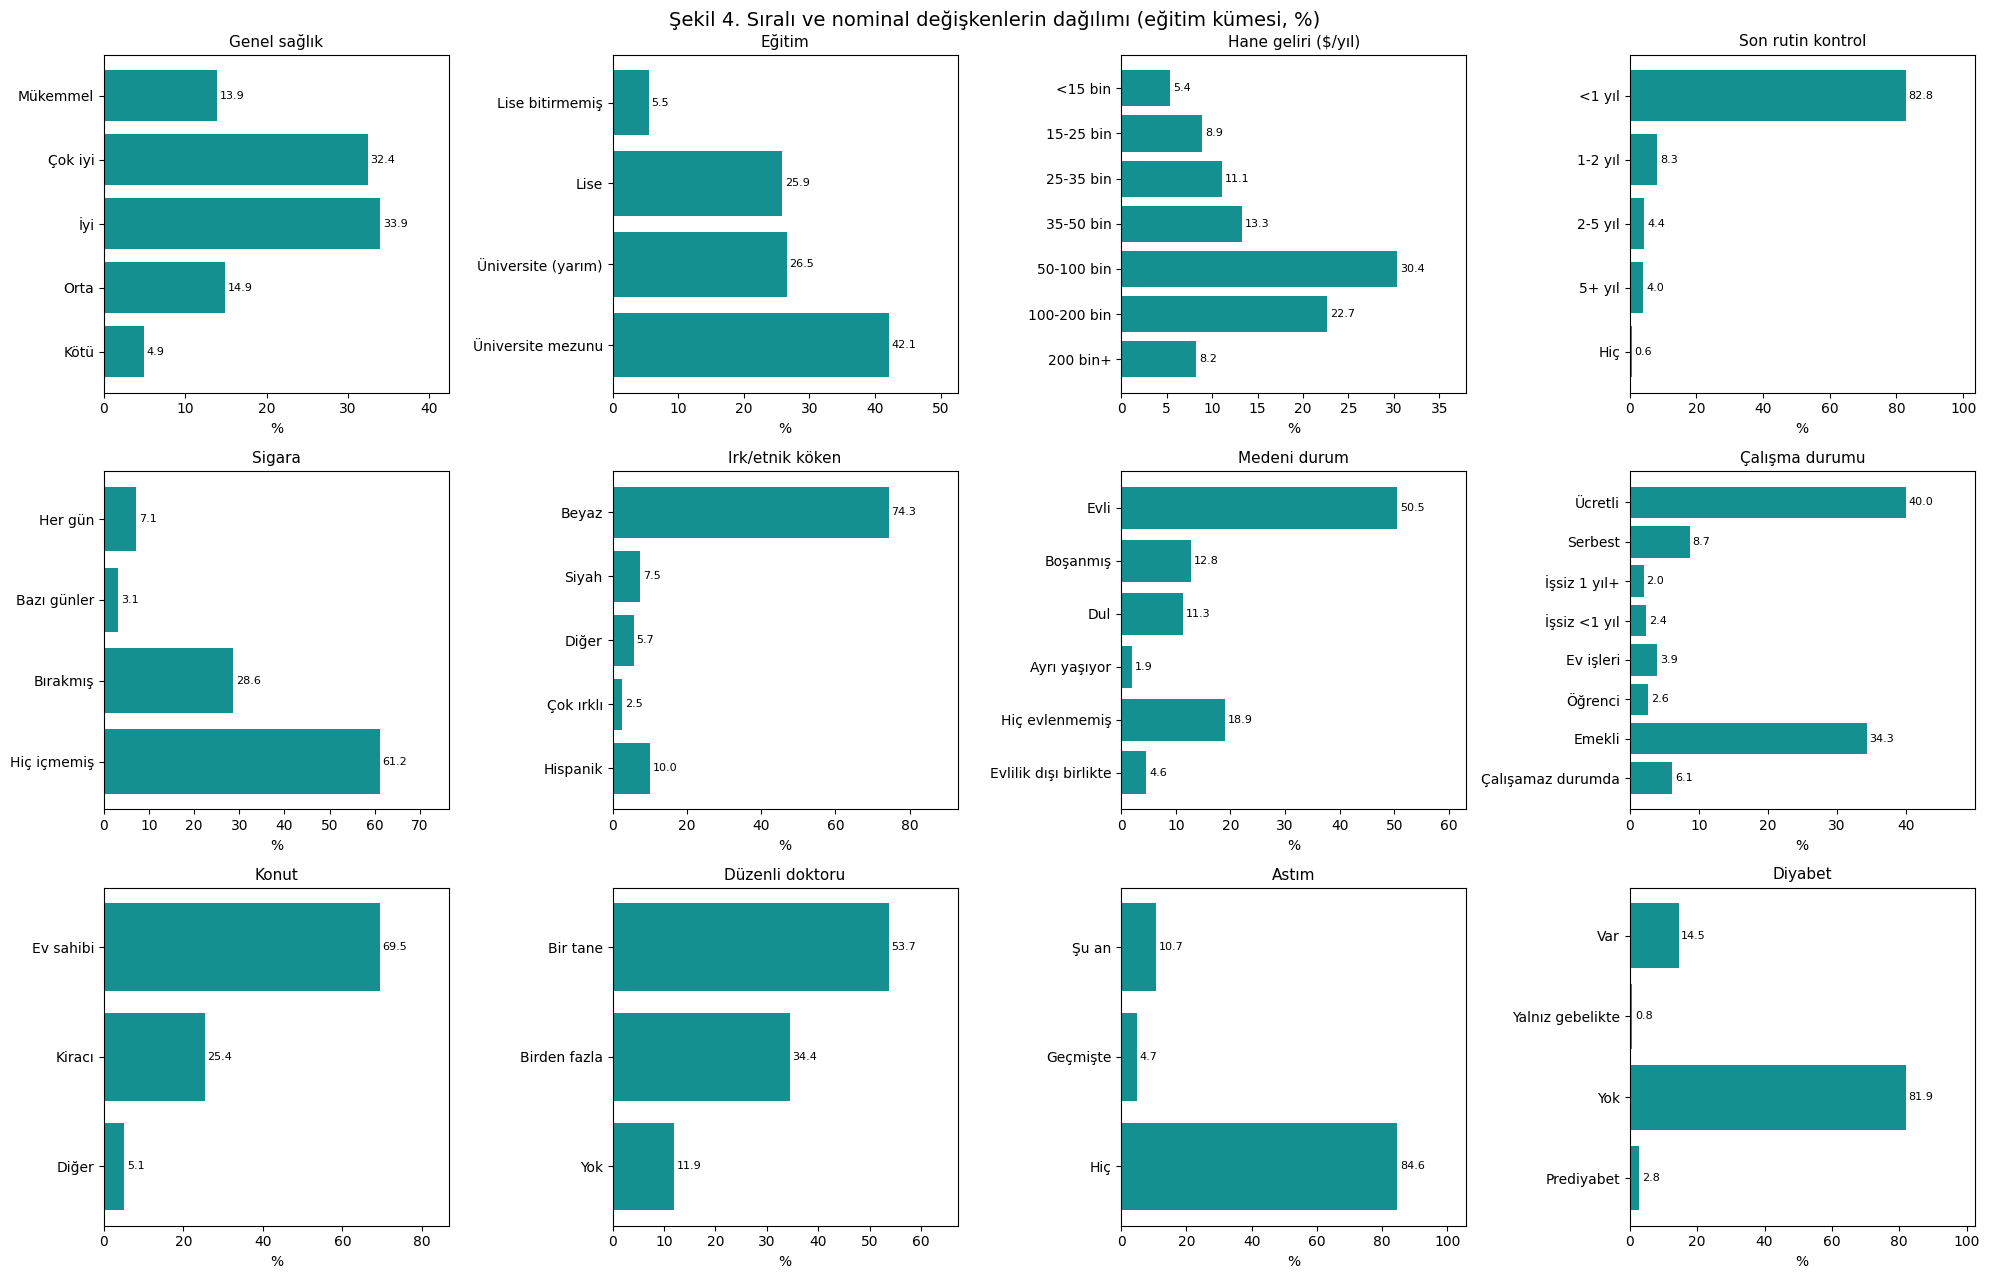

In [14]:
ETIKET = {
    'GENHLTH':  ('Genel sağlık', {1: 'Mükemmel', 2: 'Çok iyi', 3: 'İyi', 4: 'Orta', 5: 'Kötü'}),
    '_EDUCAG':  ('Eğitim', {1: 'Lise bitirmemiş', 2: 'Lise', 3: 'Üniversite (yarım)', 4: 'Üniversite mezunu'}),
    '_INCOMG1': ('Hane geliri ($/yıl)', {1: '<15 bin', 2: '15-25 bin', 3: '25-35 bin', 4: '35-50 bin',
                                         5: '50-100 bin', 6: '100-200 bin', 7: '200 bin+'}),
    'CHECKUP1': ('Son rutin kontrol', {1: '<1 yıl', 2: '1-2 yıl', 3: '2-5 yıl', 4: '5+ yıl', 5: 'Hiç'}),
    '_SMOKER3': ('Sigara', {1: 'Her gün', 2: 'Bazı günler', 3: 'Bırakmış', 4: 'Hiç içmemiş'}),
    '_RACEGR3': ('Irk/etnik köken', {1: 'Beyaz', 2: 'Siyah', 3: 'Diğer', 4: 'Çok ırklı', 5: 'Hispanik'}),
    'MARITAL':  ('Medeni durum', {1: 'Evli', 2: 'Boşanmış', 3: 'Dul', 4: 'Ayrı yaşıyor',
                                  5: 'Hiç evlenmemiş', 6: 'Evlilik dışı birlikte'}),
    'EMPLOY1':  ('Çalışma durumu', {1: 'Ücretli', 2: 'Serbest', 3: 'İşsiz 1 yıl+', 4: 'İşsiz <1 yıl',
                                    5: 'Ev işleri', 6: 'Öğrenci', 7: 'Emekli', 8: 'Çalışamaz durumda'}),
    'RENTHOM1': ('Konut', {1: 'Ev sahibi', 2: 'Kiracı', 3: 'Diğer'}),
    'PERSDOC3': ('Düzenli doktoru', {1: 'Bir tane', 2: 'Birden fazla', 3: 'Yok'}),
    '_ASTHMS1': ('Astım', {1: 'Şu an', 2: 'Geçmişte', 3: 'Hiç'}),
    'DIABETE4': ('Diyabet', {1: 'Var', 2: 'Yalnız gebelikte', 3: 'Yok', 4: 'Prediyabet'}),
}

fig, axes = plt.subplots(3, 4, figsize=(20, 13))
for ax, (s, (baslik, etiketler)) in zip(axes.flat, ETIKET.items()):
    yuzde = egitim[s].value_counts(normalize=True).reindex(list(etiketler)) * 100
    cubuklar = ax.barh([etiketler[k] for k in yuzde.index], yuzde.values, color='#159090')
    ax.bar_label(cubuklar, fmt='%.1f', padding=2, fontsize=8)
    ax.invert_yaxis()                 # kod sırası yukarıdan aşağıya
    ax.set_xlim(0, yuzde.max() * 1.25)
    ax.set_title(baslik, fontsize=11)
    ax.set_xlabel('%')
fig.suptitle('Şekil 4. Sıralı ve nominal değişkenlerin dağılımı (eğitim kümesi, %)', fontsize=14)
plt.tight_layout()
plt.show()

**Yorum (Şekil 4):** Katılımcıların %19,8'i genel sağlığını "orta" ya da "kötü" olarak değerlendirmektedir. Örneklemde üniversite mezunları (%42,1), beyazlar (%74,3) ve emekliler (%34,3) ABD nüfusuna göre fazla temsil edilmektedir (codebook'taki ağırlıklı oranlar sırasıyla yaklaşık %32, %59 ve %21); bu, anket ağırlıklarının kullanılmamasından kaynaklanan bir sınırlılıktır. Katılımcıların %6,1'i çalışamaz durumdadır. Diyabette "yalnızca gebelikte" kategorisi çok nadirdir (%0,8); öznitelik mühendisliğinde "yok" kategorisiyle birleştirilecektir.

### 6.3 Değişkenlerin hedefle ilişkisi
Her değişkenin gruplarında sık ruhsal sıkıntı oranı hesaplanmış ve genel oranla (%14,4, kesikli çizgi) karşılaştırılmıştır. Sayısal değişkenler yalnızca bu görselleştirme için anlamlı aralıklara bölünmüştür; modelde sayısal halleriyle kullanılacaktır. İlişkinin gücü Cramér's V ile ölçülmüştür (0 = ilişki yok, 1 = tam ilişki; yaklaşık 0,1 zayıf, 0,3 orta, 0,5 güçlü). Örneklem çok büyük olduğu için ki-kare testinin p değeri hemen her değişkende sıfıra yakın çıkar; bu nedenle karar için p değeri değil, örneklem büyüklüğünden bağımsız olan Cramér's V kullanılmıştır.

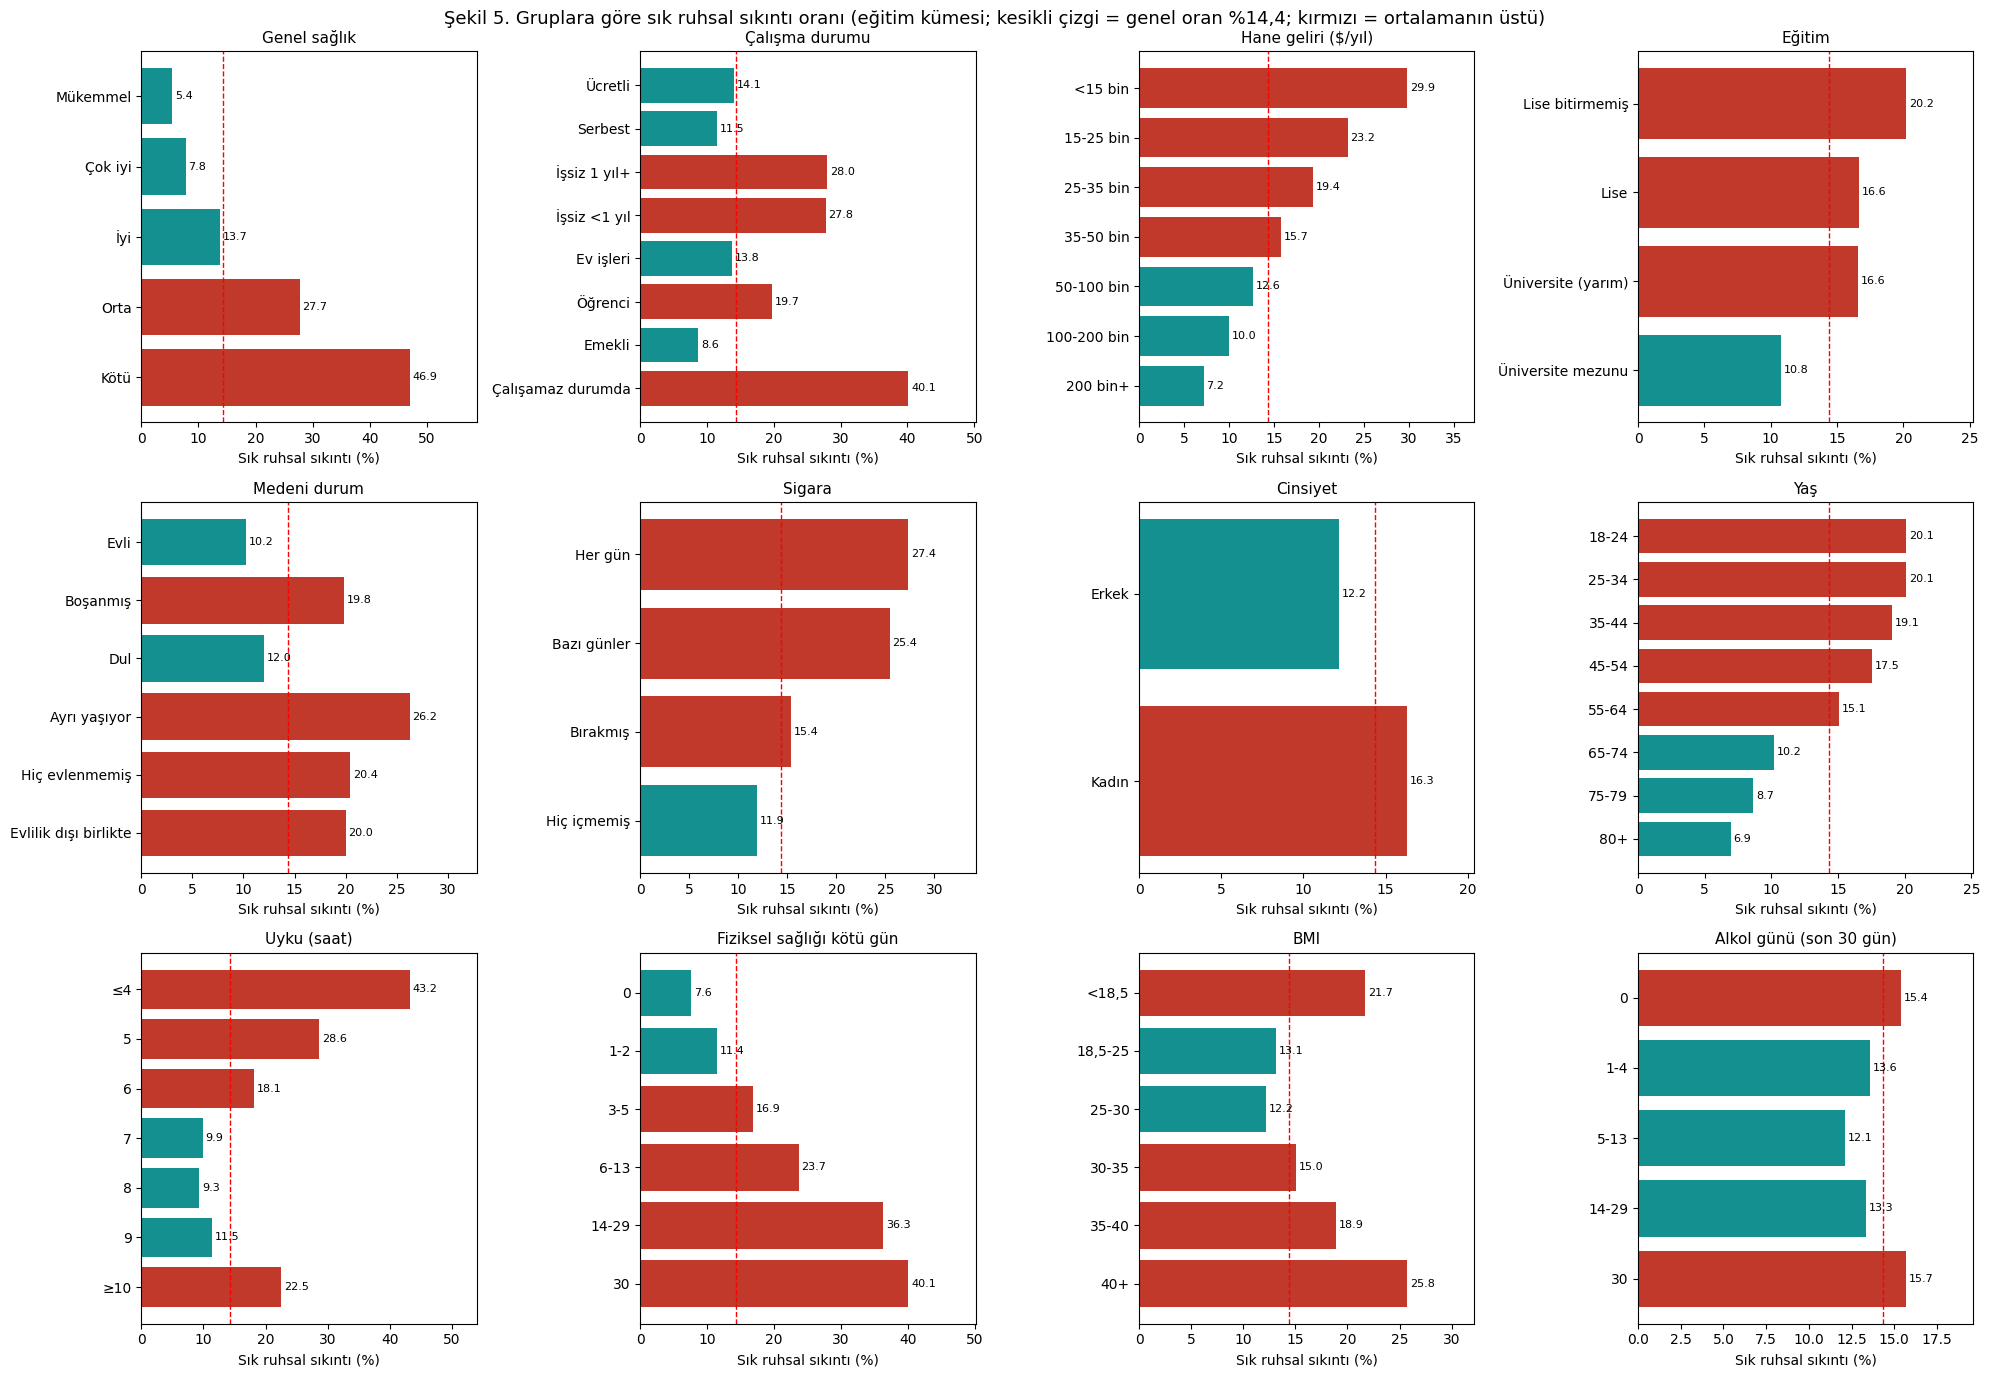

In [15]:
GENEL = egitim['hedef'].mean() * 100

# Grafik için gruplanmış değişkenler (tek tablo)
grup = pd.DataFrame(index=egitim.index)
for s in ['GENHLTH', 'EMPLOY1', '_INCOMG1', '_EDUCAG', 'MARITAL', '_SMOKER3']:
    baslik, etiketler = ETIKET[s]
    grup[baslik] = pd.Categorical(egitim[s].map(etiketler), categories=list(etiketler.values()), ordered=True)
grup['Cinsiyet'] = pd.Categorical(egitim['SEXVAR'].map({1: 'Erkek', 2: 'Kadın'}), categories=['Erkek', 'Kadın'])
grup['Yaş'] = pd.cut(egitim['_AGE80'], [17, 24, 34, 44, 54, 64, 74, 79, 80],
                     labels=['18-24', '25-34', '35-44', '45-54', '55-64', '65-74', '75-79', '80+'])
grup['Uyku (saat)'] = pd.cut(egitim['SLEPTIM1'], [0, 4, 5, 6, 7, 8, 9, 24],
                             labels=['≤4', '5', '6', '7', '8', '9', '≥10'])
grup['Fiziksel sağlığı kötü gün'] = pd.cut(egitim['PHYSHLTH'], [-1, 0, 2, 5, 13, 29, 30],
                                           labels=['0', '1-2', '3-5', '6-13', '14-29', '30'])
grup['BMI'] = pd.cut(egitim['_BMI5'], [0, 18.5, 25, 30, 35, 40, 100], right=False,
                     labels=['<18,5', '18,5-25', '25-30', '30-35', '35-40', '40+'])
grup['Alkol günü (son 30 gün)'] = pd.cut(egitim['ALKOL_GUN'], [-1, 0, 4.3, 12.9, 29.9, 30],
                                         labels=['0', '1-4', '5-13', '14-29', '30'])

fig, axes = plt.subplots(3, 4, figsize=(20, 14))
for ax, sutun in zip(axes.flat, grup.columns):
    oran = egitim.groupby(grup[sutun], observed=True)['hedef'].mean() * 100
    renk = ['#C0392B' if v > GENEL else '#159090' for v in oran.values]
    cubuklar = ax.barh(oran.index.astype(str), oran.values, color=renk)
    ax.bar_label(cubuklar, fmt='%.1f', padding=2, fontsize=8)
    ax.axvline(GENEL, color='red', ls='--', lw=1)
    ax.invert_yaxis()
    ax.set_xlim(0, oran.max() * 1.25)
    ax.set_title(sutun, fontsize=11)
    ax.set_xlabel('Sık ruhsal sıkıntı (%)')
fig.suptitle('Şekil 5. Gruplara göre sık ruhsal sıkıntı oranı (eğitim kümesi; kesikli çizgi = genel oran %14,4; kırmızı = ortalamanın üstü)', fontsize=13)
plt.tight_layout()
plt.show()

**Yorum (Şekil 5):** Sık ruhsal sıkıntı genel sağlık kötüleştikçe keskin biçimde artar (mükemmel %5,4 → kötü %46,9). Belirgin bir sosyoekonomik eğim vardır: hane geliri en düşük grupta oran %29,9, en yüksek grupta %7,2'dir; çalışamaz durumda olanlarda %40,1, işsizlerde yaklaşık %28'dir. Oran gençlerde daha yüksektir (18-24 yaş %20,1, 80+ yaş %6,9); kadınlarda (%16,3) erkeklerden (%12,2) yüksektir; her gün sigara içenlerde (%27,4) hiç içmeyenlerin (%11,9) iki katından fazladır. Uyku ve BMI ile ilişki doğrusal değil U biçimlidir: 4 saat ve altı uyuyanlarda %43,2, 7-8 saat uyuyanlarda yaklaşık %9,5, 10 saat ve üzeri uyuyanlarda %22,5; BMI'de zayıf (%21,7) ve ileri obez (%25,8) gruplar en yüksek risktedir. Bu doğrusal olmayan ilişkiler öznitelik mühendisliğinde yeni değişkenlerle (ideal uykudan sapma, BMI kategorileri) modele aktarılacaktır. Alkol günü ile hedef arasında belirgin bir ilişki görülmemektedir.

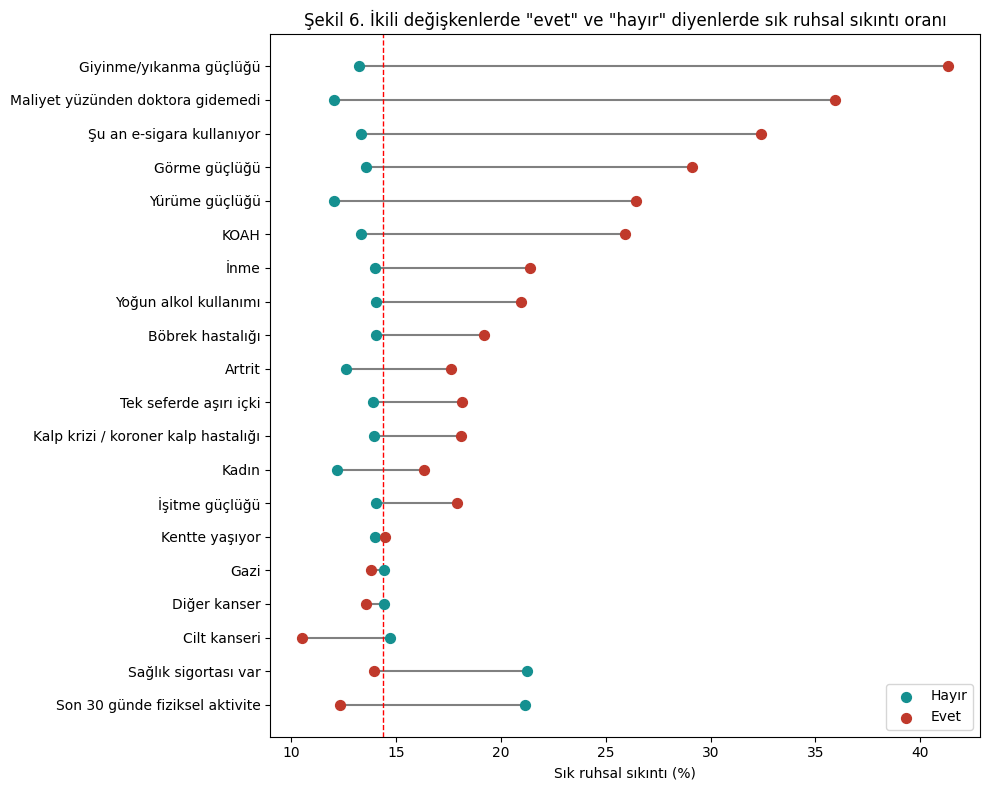

In [16]:
satirlar = []
for s, (kod, ad) in IKILI.items():
    evet = egitim[s] == kod
    hayir = egitim[s].notna() & ~evet
    satirlar.append({'degisken': ad,
                     'hayır': egitim.loc[hayir, 'hedef'].mean() * 100,
                     'evet': egitim.loc[evet, 'hedef'].mean() * 100})
ikili_oran = pd.DataFrame(satirlar).set_index('degisken')
ikili_oran['fark'] = ikili_oran['evet'] - ikili_oran['hayır']
ikili_oran = ikili_oran.sort_values('fark')

fig, ax = plt.subplots(figsize=(10, 8))
for i, (ad, r) in enumerate(ikili_oran.iterrows()):
    ax.plot([r['hayır'], r['evet']], [i, i], color='grey', lw=1.5)
ax.scatter(ikili_oran['hayır'], range(len(ikili_oran)), color='#159090', s=50, label='Hayır', zorder=3)
ax.scatter(ikili_oran['evet'], range(len(ikili_oran)), color='#C0392B', s=50, label='Evet', zorder=3)
ax.set_yticks(range(len(ikili_oran)))
ax.set_yticklabels(ikili_oran.index)
ax.axvline(GENEL, color='red', ls='--', lw=1)
ax.set_xlabel('Sık ruhsal sıkıntı (%)')
ax.set_title('Şekil 6. İkili değişkenlerde "evet" ve "hayır" diyenlerde sık ruhsal sıkıntı oranı')
ax.legend()
plt.tight_layout()
plt.show()

**Yorum (Şekil 6):** En büyük farklar işlevsel güçlüklerde (giyinme/yıkanma, görme, yürüme), maliyet yüzünden doktora gidememede ve e-sigara kullanımında görülmektedir. Sağlık sigortası olmayanlarda ve son 30 günde fiziksel aktivite yapmayanlarda oran yaklaşık %21'dir. Cilt kanseri olanlarda oranın daha düşük olması, bu grubun ortalamada daha yaşlı olmasıyla (yaş arttıkça sıkıntı azalmaktadır) açıklanabilir; bu tür ilişkiler nedensellik olarak yorumlanmamalıdır. Gazi olma, kentte yaşama ve diğer kanser türleri hedefle neredeyse ilişkisizdir.

In [17]:
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    tablo = pd.crosstab(x, y)                       # eksikler otomatik dışarıda kalır
    chi2 = chi2_contingency(tablo, correction=False)[0]
    n = tablo.to_numpy().sum()
    return np.sqrt(chi2 / (n * (min(tablo.shape) - 1)))

# Tüm kategorik ve ikili değişkenler (kod hali) + gruplanmış sayısallar + eyalet
adlar = {s: ETIKET[s][0] for s in ETIKET}
adlar.update({s: ad for s, (kod, ad) in IKILI.items()})
adlar['_STATE'] = 'Eyalet'
sonuc = {ad: cramers_v(egitim[s], egitim['hedef']) for s, ad in adlar.items()}
for sutun in ['Yaş', 'Uyku (saat)', 'Fiziksel sağlığı kötü gün', 'BMI', 'Alkol günü (son 30 gün)']:
    sonuc[sutun + ' (gruplu)'] = cramers_v(grup[sutun], egitim['hedef'])
sonuc['Çocuk sayısı (0/1/2/3/4+)'] = cramers_v(egitim['CHILDREN'].clip(upper=4), egitim['hedef'])

tablo4 = pd.Series(sonuc).sort_values(ascending=False).round(3).to_frame("Cramér's V")
print("Tablo 4. Değişkenlerin hedefle ilişki gücü (Cramér's V, eğitim kümesi)")
display(tablo4)

Tablo 4. Değişkenlerin hedefle ilişki gücü (Cramér's V, eğitim kümesi)


,Cramér's V
Fiziksel sağlığı kötü gün (gruplu),0.312
Genel sağlık,0.291
Çalışma durumu,0.224
Uyku (saat) (gruplu),0.220
Maliyet yüzünden doktora gidemedi,0.202
Hane geliri ($/yıl),0.161
Giyinme/yıkanma güçlüğü,0.160
Yürüme güçlüğü,0.152
Medeni durum,0.141
Konut,0.140


**Yorum (Tablo 4):** Hedefle en güçlü ilişkili değişkenler fiziksel sağlığı kötü gün sayısı (V = 0,31) ve genel sağlık (0,29) olup orta düzeydedir; bunları çalışma durumu (0,22), uyku (0,22), maliyet yüzünden doktora gidememe (0,20) ve gelir (0,16) izler. Alkol günü (0,03), diğer kanser (0,008), gazi olma (0,006) ve kentte yaşama (0,005) neredeyse ilişkisizdir; bu değişkenlerin öznitelik seçiminde elenmesi beklenir. Tek değişkenli bu sıralama, değişkenlerin birlikte etkisini göstermez; nihai seçim öznitelik seçimi yöntemleriyle yapılacaktır.

### 6.4 Öznitelikler arası ilişki
Sayısal, sıralı ve ikili öznitelikler arasındaki ilişki Spearman sıra korelasyonuyla incelenmiştir. Spearman, değişkenlerin sıralamasına baktığı için hem sıralı kategorilere hem de çarpık ve aykırı değer içeren sayısal değişkenlere uygundur (Pearson yalnızca doğrusal ilişkiyi ölçer ve uç değerlerden etkilenir). Amaç, birbirinin tekrarı olan öznitelikleri belirlemektir: çok yüksek korelasyonlu öznitelikler aynı bilgiyi taşır ve doğrusal modellerde katsayıları kararsızlaştırır (çoklu doğrusal bağlantı).
Yön notu: genel sağlıkta büyük değer = kötü sağlık; gelir ve eğitimde büyük değer = yüksek; sigarada büyük değer = daha az sigara (4 = hiç içmemiş); son kontrolde büyük değer = daha uzun süre önce. İkili değişkenlerde 1 = evet.

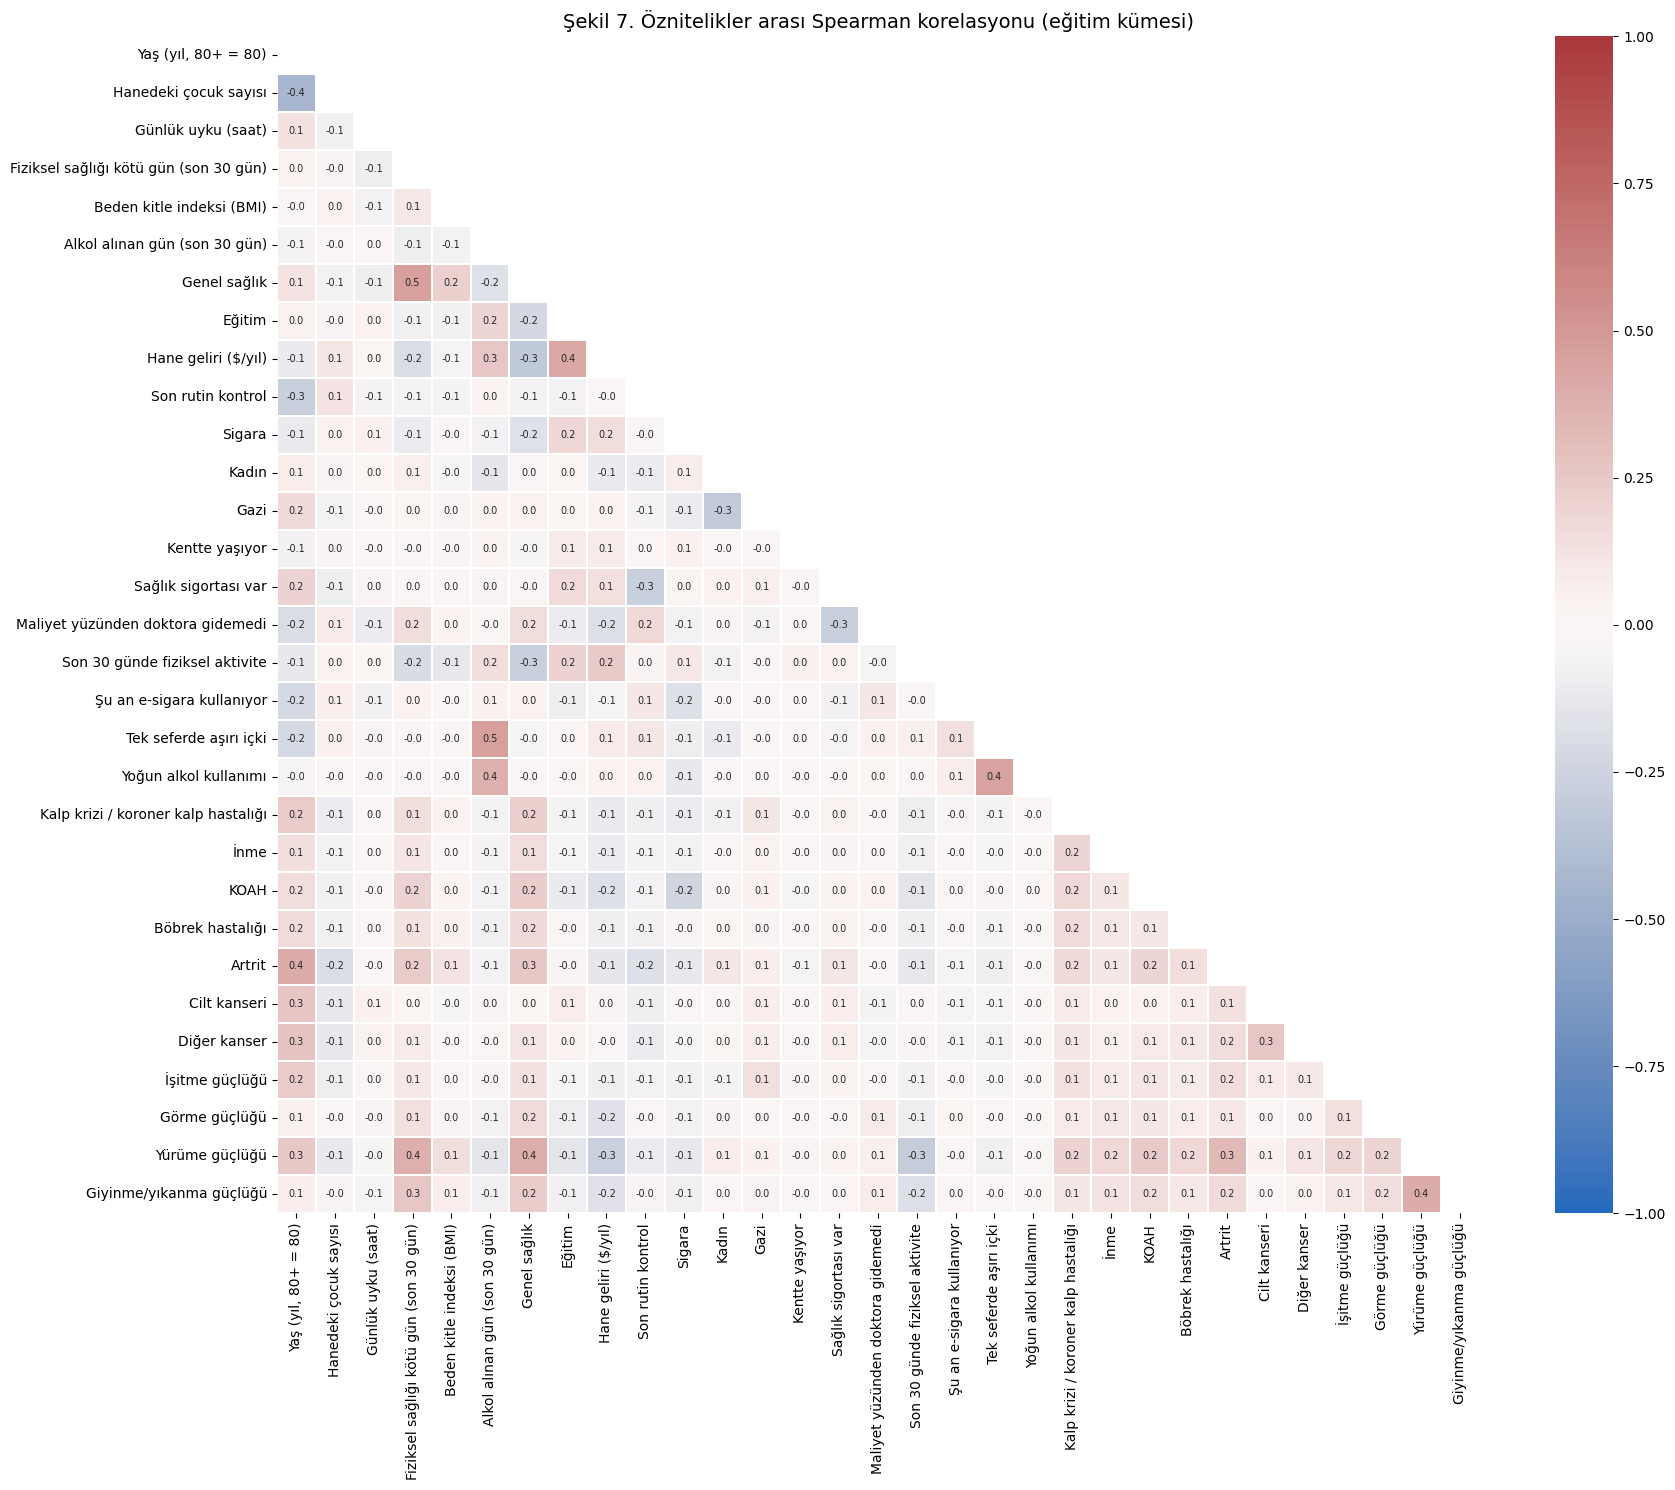

Tablo 5. En yüksek korelasyonlu 15 öznitelik çifti


,,Spearman r
Fiziksel sağlığı kötü gün (son 30 gün),Genel sağlık,0.46
Alkol alınan gün (son 30 gün),Tek seferde aşırı içki,0.46
Tek seferde aşırı içki,Yoğun alkol kullanımı,0.45
"Yaş (yıl, 80+ = 80)",Hanedeki çocuk sayısı,-0.43
Eğitim,Hane geliri ($/yıl),0.42
Yürüme güçlüğü,Giyinme/yıkanma güçlüğü,0.40
"Yaş (yıl, 80+ = 80)",Artrit,0.39
Genel sağlık,Yürüme güçlüğü,0.39
Fiziksel sağlığı kötü gün (son 30 gün),Yürüme güçlüğü,0.38
Alkol alınan gün (son 30 gün),Yoğun alkol kullanımı,0.37


|r| > 0,95 olan çift sayısı: 0
|r| > 0,70 olan çift sayısı: 0


In [18]:
SIRALI = ['GENHLTH', '_EDUCAG', '_INCOMG1', 'CHECKUP1', '_SMOKER3']

# Sayısal + sıralı değişkenler (Türkçe adlarla) + ikili değişkenler (1 = evet, 0 = hayır)
korel = egitim[list(SAYISAL) + SIRALI].rename(
    columns={**SAYISAL, **{s: ETIKET[s][0] for s in SIRALI}})
for s, (kod, ad) in IKILI.items():
    korel[ad] = (egitim[s] == kod).astype(float).where(egitim[s].notna())

kor = korel.corr(method='spearman')          # yaklaşık 15-30 saniye sürebilir

maske = np.triu(np.ones_like(kor, dtype=bool))   # üst üçgen tekrar olduğu için gizlenir
plt.figure(figsize=(18, 15))
sns.heatmap(kor, mask=maske, annot=True, fmt='.1f', annot_kws={'size': 7},
            cmap='vlag', vmin=-1, vmax=1, linewidths=0.3)
plt.title('Şekil 7. Öznitelikler arası Spearman korelasyonu (eğitim kümesi)', fontsize=14)
plt.tight_layout()
plt.show()

# Mutlak değeri en yüksek 15 çift
ust = kor.where(np.triu(np.ones(kor.shape, dtype=bool), k=1)).stack()
ciftler = ust.reindex(ust.abs().sort_values(ascending=False).index).head(15).round(2)
print('Tablo 5. En yüksek korelasyonlu 15 öznitelik çifti')
display(ciftler.to_frame('Spearman r'))
print('|r| > 0,95 olan çift sayısı:', (ust.abs() > 0.95).sum())
print('|r| > 0,70 olan çift sayısı:', (ust.abs() > 0.70).sum())

**Yorum (Şekil 7, Tablo 5):** Öznitelikler arasındaki ilişkiler genel olarak zayıf-orta düzeydedir; en yüksek mutlak korelasyon 0,46'dır (fiziksel sağlığı kötü gün – genel sağlık; alkol günü – tek seferde aşırı içki). |r| > 0,70 olan hiçbir çift yoktur; dolayısıyla ciddi bir çoklu doğrusal bağlantı beklenmemektedir ve |r| > 0,95 filtresi hiçbir özniteliği elemeyecektir. Bu, değişken seçimi aşamasında birebir tekrar eden değişkenlerin (_SEX, EXERANY2, _AGEG5YR gibi) baştan çıkarılmış olmasıyla tutarlıdır. Beklenen ilişkiler doğrulanmıştır: yaş ile hanedeki çocuk sayısı ters yönlü (−0,43), eğitim ile gelir aynı yönlü (0,42), yürüme ile giyinme güçlüğü aynı yönlüdür (0,40).

### 6.5 Aykırı değer analizi
Üç yöntem karşılaştırılmıştır: (1) IQR / Tukey çitleri: Q1 − 1,5·IQR altı ve Q3 + 1,5·IQR üstü; (2) Z-skor: ortalamadan 3 standart sapmadan fazla uzak değerler (normal dağılım varsayar); (3) Isolation Forest: birden çok değişkeni birlikte değerlendiren, "kolay yalıtılan" gözlemleri aykırı sayan çok değişkenli yöntem (%1 aykırı varsayımıyla). Yaş 18-80 aralığında sınırlı olduğu için analize alınmamıştır. Aykırı değerler otomatik silinmemiş; önce incelenmiş ve hedefle ilişkileri değerlendirilmiştir.

Tablo 6. IQR ve Z-skor yöntemlerinin karşılaştırması (eğitim kümesi)


,Q1,Q3,IQR,IQR alt sınır,IQR üst sınır,IQR aykırı %,Z üst sınır (ort + 3 ss),Z aykırı %,sıkıntı % – IQR aykırı,sıkıntı % – diğerleri
değişken,,,,,,,,,,
Çocuk sayısı,0.00,0.00,0.00,0.00,0.00,24.36,3.72,2.01,16.73,13.63
Uyku (saat),6.00,8.00,2.00,3.00,11.00,1.14,11.35,1.14,33.66,14.11
Fiziksel sağlığı kötü gün,0.00,4.00,4.00,-6.00,10.00,14.98,31.74,0.00,38.21,10.11
BMI,24.11,31.62,7.51,12.84,42.89,3.30,48.05,1.32,28.33,14.00
Alkol günü,0.00,4.30,4.30,-6.45,10.75,13.42,27.00,4.34,13.50,14.55


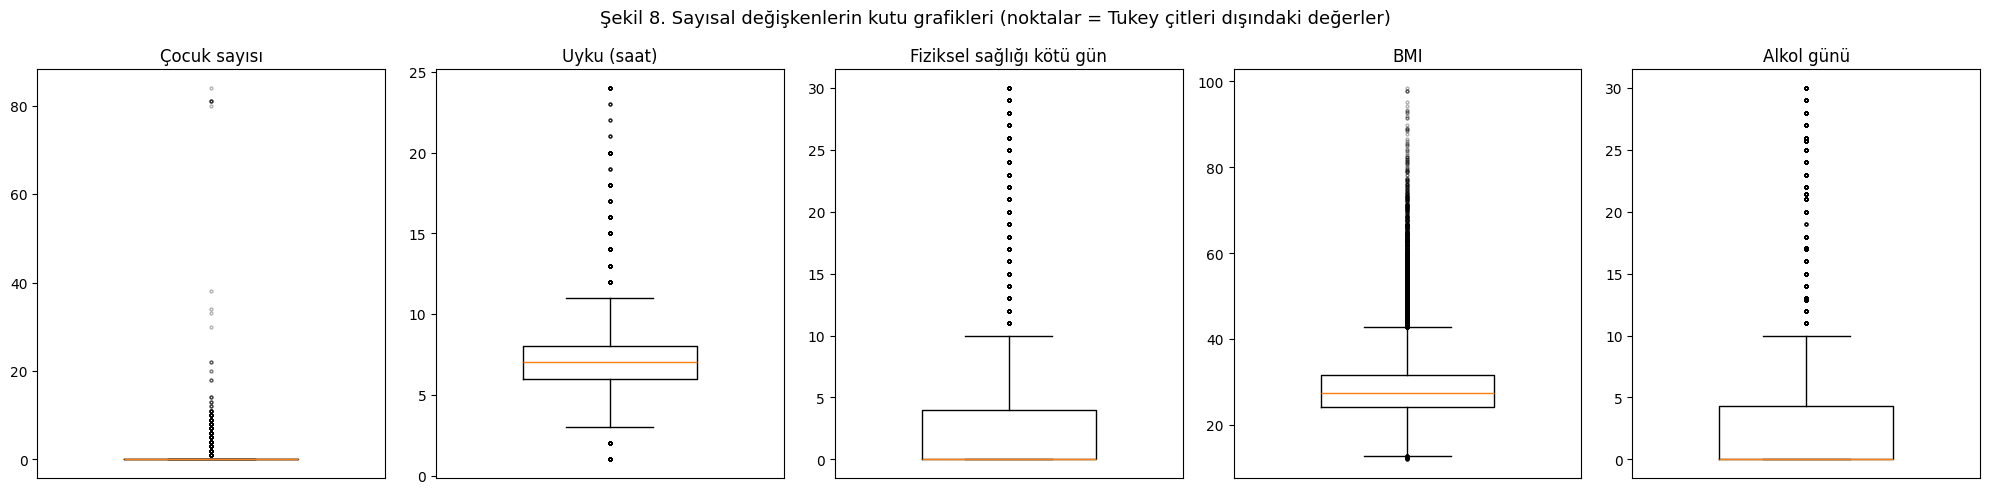

In [19]:
AYKIRI = {'CHILDREN': 'Çocuk sayısı', 'SLEPTIM1': 'Uyku (saat)',
          'PHYSHLTH': 'Fiziksel sağlığı kötü gün', '_BMI5': 'BMI', 'ALKOL_GUN': 'Alkol günü'}

satirlar = []
for s, ad in AYKIRI.items():
    x = egitim[s]
    d = x.dropna()
    q1, q3 = d.quantile([0.25, 0.75])
    iqr = q3 - q1
    alt, ust = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_m = (x < alt) | (x > ust)
    z_m = ((x - d.mean()) / d.std()).abs() > 3
    satirlar.append({
        'değişken': ad, 'Q1': q1, 'Q3': q3, 'IQR': iqr,
        'IQR alt sınır': alt, 'IQR üst sınır': ust,
        'IQR aykırı %': iqr_m.sum() / len(d) * 100,
        'Z üst sınır (ort + 3 ss)': d.mean() + 3 * d.std(),
        'Z aykırı %': z_m.sum() / len(d) * 100,
        'sıkıntı % – IQR aykırı': egitim.loc[iqr_m, 'hedef'].mean() * 100,
        'sıkıntı % – diğerleri': egitim.loc[~iqr_m & x.notna(), 'hedef'].mean() * 100,
    })
tablo6 = pd.DataFrame(satirlar).set_index('değişken').round(2)
print('Tablo 6. IQR ve Z-skor yöntemlerinin karşılaştırması (eğitim kümesi)')
display(tablo6)

fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for ax, (s, ad) in zip(axes, AYKIRI.items()):
    ax.boxplot(egitim[s].dropna(), vert=True, widths=0.5,
               flierprops={'marker': 'o', 'markersize': 2, 'alpha': 0.3})
    ax.set_title(ad)
    ax.set_xticks([])
fig.suptitle('Şekil 8. Sayısal değişkenlerin kutu grafikleri (noktalar = Tukey çitleri dışındaki değerler)', fontsize=13)
plt.tight_layout()
plt.show()

**Yorum (Tablo 6, Şekil 8):** İki yöntem dağılım yapısına göre farklı ve kısmen yanıltıcı sonuçlar vermiştir. Çocuk sayısında Q1 = Q3 = 0 olduğundan IQR = 0'dır ve IQR yöntemi çocuğu olan herkesi (%24,4) aykırı saymıştır; benzer şişme fiziksel sağlık (%15,0) ve alkol gününde (%13,4) de vardır. Sıfırda yığılmış sayım değişkenlerinde IQR yöntemi uygun değildir. Z-skor ise fiziksel sağlıkta hiç aykırı bulamamıştır, çünkü sınır (ortalama + 3 ss = 31,7) değişkenin üst sınırı olan 30'u aşmaktadır; normal dağılım varsayımı çarpık ve sınırlı değişkenlerde geçerli değildir. Uyku ve BMI'de iki yöntem daha tutarlıdır (uyku: 3 saatin altı ve 11 saatin üstü; BMI: yaklaşık 43-48 üstü). IQR ile aykırı bulunanlarda sık ruhsal sıkıntı oranı belirgin biçimde yüksektir (uyku %33,7, fiziksel sağlık %38,2, BMI %28,3; diğerlerinde %10-14).

In [20]:
kurallar = {
    'Çocuk sayısı > 10':         egitim['CHILDREN'] > 10,
    'Uyku < 3 saat':             egitim['SLEPTIM1'] < 3,
    'Uyku > 16 saat':            egitim['SLEPTIM1'] > 16,
    'BMI < 15':                  egitim['_BMI5'] < 15,
    'BMI > 60':                  egitim['_BMI5'] > 60,
}
tablo7 = pd.DataFrame({
    'kişi': {k: m.sum() for k, m in kurallar.items()},
    'oran %': {k: m.sum() / len(egitim) * 100 for k, m in kurallar.items()},
    'sıkıntı %': {k: egitim.loc[m, 'hedef'].mean() * 100 for k, m in kurallar.items()},
}).round(3)
print('Tablo 7. Alan bilgisine göre şüpheli değerler (eğitim kümesi; genel sıkıntı oranı %14,4)')
display(tablo7)

Tablo 7. Alan bilgisine göre şüpheli değerler (eğitim kümesi; genel sıkıntı oranı %14,4)


,kişi,oran %,sıkıntı %
Çocuk sayısı > 10,43,0.015,32.558
Uyku < 3 saat,459,0.164,48.584
Uyku > 16 saat,198,0.071,36.869
BMI < 15,300,0.107,21.333
BMI > 60,514,0.184,36.770


**Yorum (Tablo 7):** Alan bilgisine göre şüpheli değerler çok az sayıdadır (her kural için eğitim kümesinin %0,2'sinden azı). Hanede 10'dan fazla çocuk (43 kişi) olası bir veri girişi hatasıdır; ancak 3 saatten az uyku (%48,6), 60'ın üzerinde BMI (%36,8) ve 16 saatten fazla uyku (%36,9) gruplarında sık ruhsal sıkıntı oranı genel oranın 2,5-3,5 katıdır. Bu değerler büyük olasılıkla ölçüm hatası değil, gerçek ve klinik olarak anlamlı uç durumlardır.

In [21]:
from sklearn.ensemble import IsolationForest

# Isolation Forest eksik değer kabul etmez; yalnızca bu analiz için eksikler medyanla dolduruldu
X_if = egitim[list(AYKIRI)].fillna(egitim[list(AYKIRI)].median())
iso = IsolationForest(contamination=0.01, random_state=RANDOM_STATE, n_jobs=-1)
if_aykiri = iso.fit_predict(X_if) == -1          # -1 = aykırı

print(f'Isolation Forest aykırı: {if_aykiri.sum():,} kişi (%{if_aykiri.mean()*100:.1f})')
print(f'Sık ruhsal sıkıntı – aykırılarda: %{egitim.loc[if_aykiri, "hedef"].mean()*100:.1f} | '
      f'diğerlerinde: %{egitim.loc[~if_aykiri, "hedef"].mean()*100:.1f}')
print('\nTablo 8. Isolation Forest aykırılarının özellikleri (medyan) – diğerleriyle karşılaştırma')
display(pd.DataFrame({'aykırılar': X_if[if_aykiri].median(),
                      'diğerleri': X_if[~if_aykiri].median()}).rename(index=AYKIRI).round(1))

Isolation Forest aykırı: 2,798 kişi (%1.0)
Sık ruhsal sıkıntı – aykırılarda: %49.6 | diğerlerinde: %14.0

Tablo 8. Isolation Forest aykırılarının özellikleri (medyan) – diğerleriyle karşılaştırma


,aykırılar,diğerleri
Çocuk sayısı,1.0,0.0
Uyku (saat),6.0,7.0
Fiziksel sağlığı kötü gün,30.0,0.0
BMI,33.3,27.4
Alkol günü,15.0,0.0


**Yorum (Tablo 8):** Isolation Forest, beş sayısal değişkeni birlikte değerlendirerek kişilerin %1'ini (2.798 kişi) aykırı olarak işaretlemiştir. Bu grupta sık ruhsal sıkıntı oranı %49,6'dır (diğerlerinde %14,0; yaklaşık 3,5 kat). Aykırıların tipik profili ayın tamamında fiziksel sağlığı kötü (medyan 30 gün), sık alkol alan (medyan 15 gün) ve BMI'si yüksek (medyan 33,3) kişilerdir.

**Karar:** Aykırı değerler silinmemiştir. Bu değerler gürültüden çok, hedef sınıfın en yoğun bulunduğu yüksek riskli grupları temsil etmektedir; silinmeleri modeli sistematik olarak yanlı hale getirirdi. Modelleme için şu dönüşümler uygulanacaktır: çocuk sayısı 4'te kırpılacaktır (0/1/2/3/4+; 10'un üzerindeki olası hatalı değerler de böylece etkisizleşir); uyku için ideal uykudan sapma değişkeni, BMI için WHO kategorileri eklenecektir.

## 7. Özet, sınırlılıklar ve sonraki adımlar

**Özet.**
- Analiz örneklemi 349.674 kişidir (hedefi bilinmeyen 6.484 kişi çıkarıldı); sık ruhsal sıkıntı oranı %14,4'tür (yaklaşık 1:6 dengesiz). Veri, keşifsel analizden önce katmanlı olarak %80 eğitim (279.739) ve %20 test (69.935) olarak ayrılmıştır.
- Cevapsızlık kodları eksik değere çevrilmiştir. En yüksek eksiklik gelirdedir (%19,5). Uyku, tütün ve alkol sorularındaki eksiklikler aynı kişilerde birlikte görülmektedir (yarıda kalan görüşmeler). Eksikliğin hedefle ilişkisi zayıftır (−1,5 ile +0,8 puan); bu nedenle yalnızca iki eksiklik göstergesi oluşturulacaktır.
- Hedefle en güçlü ilişkili değişkenler fiziksel sağlığı kötü gün sayısı (Cramér's V = 0,31), genel sağlık (0,29), çalışma durumu (0,22), uyku (0,22), maliyet nedeniyle doktora gidememe (0,20) ve gelirdir (0,16). Uyku ve BMI ile ilişki U biçimlidir.
- Öznitelikler arasında en yüksek mutlak Spearman korelasyonu 0,46'dır; ciddi çoklu doğrusal bağlantı yoktur.
- Aykırı değerler silinmemiştir: Isolation Forest'ın işaretlediği %1'lik grupta sık ruhsal sıkıntı oranı %49,6'dır; bu değerler gürültü değil, yüksek riskli grupları temsil etmektedir.

**Sınırlılıklar.** Anket ağırlıkları kullanılmamıştır; örneklem ABD nüfusuna göre daha yaşlı, daha eğitimli ve beyaz oranı daha yüksektir. Veri kesitsel ve öz bildirime dayalıdır; gözlenen ilişkiler nedensel değildir.

**Sonraki adımlar (Notebook 2).** Öznitelik mühendisliği (çocuk sayısının kırpılması, ideal uykudan sapma, BMI kategorileri, eyaletlerin bölgelere indirgenmesi, iki eksiklik göstergesi), eğitim verisinden öğrenen ön işleme hattı, öznitelik seçimi yöntemlerinin karşılaştırılması ve lojistik regresyon ile kNN modellerinin çapraz doğrulamayla değerlendirilmesi.